# 01. Exploratory Data Analysis (EDA) — Hit Song Predictor

**Objective:** Inspect audio feature distributions, feature correlations, and relationship with the binary target `charted` (1 = appeared on Billboard Year-End Hot 100 between 2000 and 2023; 0 = uncharted Spotify track).

**Guidelines & Schema Compliance:**
- The final modelling dataset is loaded from `data/processed/songs.parquet` (7,403 tracks with a controlled 10:1 class ratio).
- Natural class balance before downsampling is inspected using `data/processed/songs_full.parquet` (80,237 deduplicated tracks).
- `chart_year` represents the Billboard chart year and must **not** be interpreted as the recording's release year (the dataset contains no `release_year` feature).
- All plotting and statistical logic is imported from `src.eda`.


In [1]:
import os
import sys
# Ensure repository root is on Python module search path
sys.path.insert(0, os.path.abspath(".."))

import pandas as pd
import matplotlib.pyplot as plt
from src.eda import (
    AUDIO_FEATURES,
    plot_class_balance_natural,
    plot_class_balance_modeling,
    plot_tempo_distribution,
    plot_valence_distribution,
    plot_danceability_vs_energy,
    plot_correlation_heatmap,
    plot_duration_by_year,
    plot_feature_boxplots,
    compute_target_correlations,
)

# Load modelling dataset and full dataset
df = pd.read_parquet("../data/processed/songs.parquet")
df_full = pd.read_parquet("../data/processed/songs_full.parquet")

print(f"Modelling dataset shape: {df.shape}")
print(f"Full dataset shape: {df_full.shape}")
print("\nColumns in modelling table:\n", df.dtypes)


Modelling dataset shape: (7403, 13)
Full dataset shape: (80237, 13)

Columns in modelling table:
 tempo               float64
energy              float64
danceability        float64
valence             float64
loudness            float64
acousticness        float64
instrumentalness    float64
speechiness         float64
duration_sec        float64
genre                   str
charted               int64
primary_artist          str
chart_year          float64
dtype: object


## 1. Natural Class Imbalance Before Downsampling

We examine the natural class distribution in the full processed dataset (`songs_full.parquet`) before downsampling.


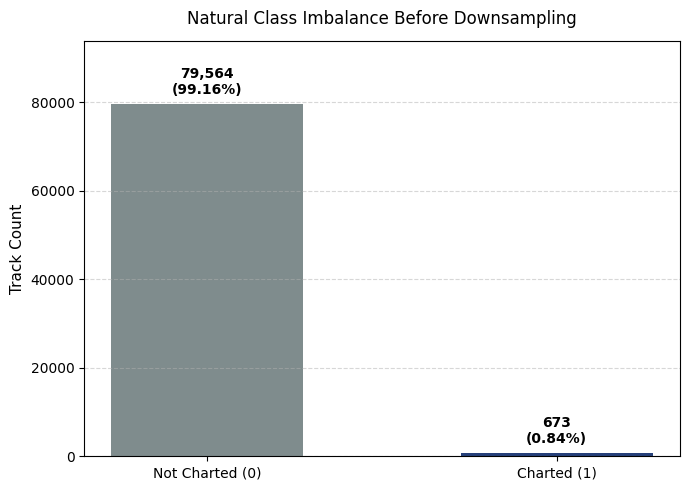

In [2]:
fig1a = plot_class_balance_natural(df_full, save_path="../reports/figures/class_balance_natural.png")


**Interpretation:**
In the full processed dataset of 80,237 tracks, 673 tracks (0.84%) charted on the Billboard Year-End Hot 100, while 79,564 tracks (99.16%) did not chart. This demonstrates the extreme natural class imbalance inherent in real-world hit song commercial performance, where non-charting songs outnumber charting hits by roughly 118 to 1. Training directly on this unadjusted distribution causes supervised classifiers to collapse into trivial majority-class predictors.


## 2. Class Balance in Final Modelling Dataset

Distribution of the 10:1 downsampled dataset (`songs.parquet`) actually used for training and evaluation.


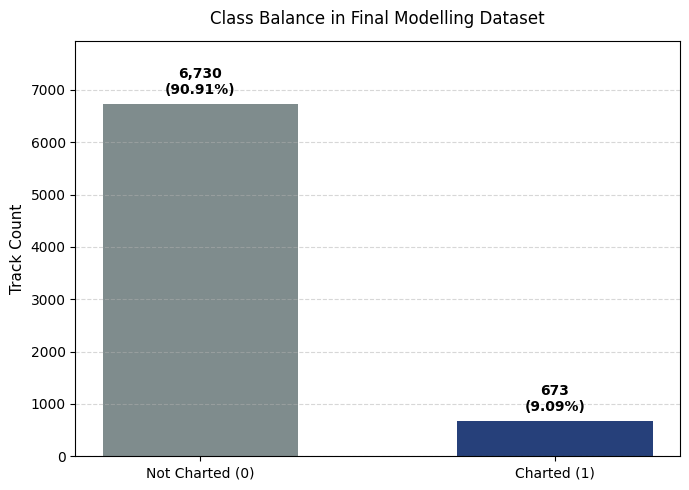

In [3]:
fig1b = plot_class_balance_modeling(df, save_path="../reports/figures/class_balance_modeling.png")


**Interpretation:**
To address the severe 118:1 natural skew while preserving all available positive signal, the final modelling dataset retains all 673 charted songs and randomly samples 10 negatives per positive (random_state=42). This yields a 7,403-track modelling table with exactly 673 charted tracks (9.09%) and 6,730 non-charted tracks (90.91%). While still imbalanced, this 10:1 ratio provides sufficient positive gradient signal for learning non-linear decision boundaries.


## 3. Tempo Distribution

Comparison of density-normalised tempo distributions between charted and non-charted tracks.


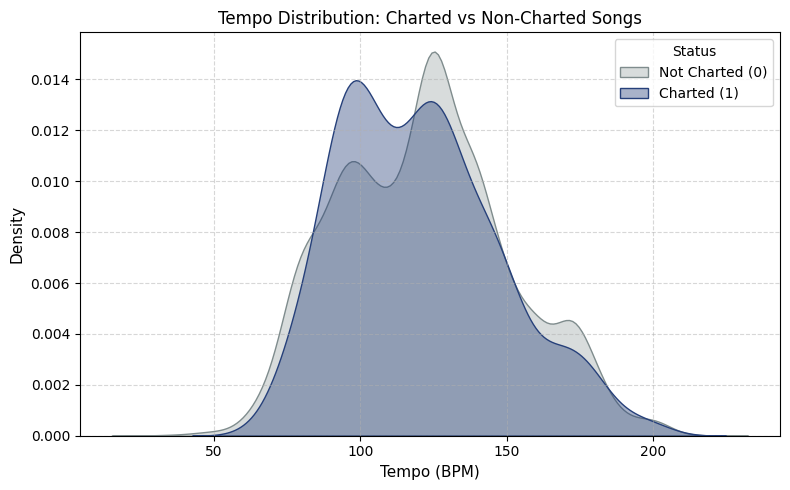

In [4]:
fig2 = plot_tempo_distribution(df, save_path="../reports/figures/tempo_distribution.png")


**Interpretation:**
The density-normalised tempo distributions for charted and non-charted tracks show near-complete overlap across the full range from 60 to 200 BPM, both peaking around typical popular music tempos between 120 and 130 BPM. The point-biserial correlation between tempo and charted status is negligible (r = -0.0152, p = 0.191). Consequently, tempo alone provides minimal discriminative separation between songs that chart and songs that do not.


## 4. Valence Distribution

Comparison of density-normalised valence (musical positiveness) distributions between classes.


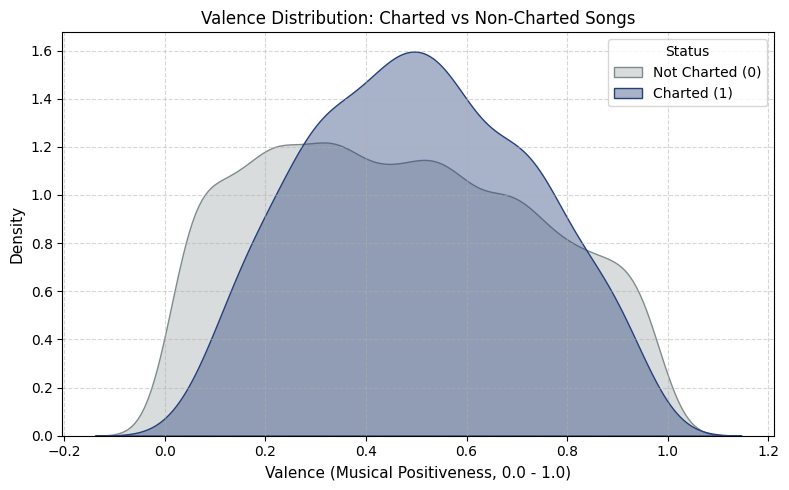

In [5]:
fig3 = plot_valence_distribution(df, save_path="../reports/figures/valence_distribution.png")


**Interpretation:**
Valence distributions for both charted and non-charted songs span the full 0.0 to 1.0 interval with extensive mutual overlap and a slight rightward shift among charted songs. While the point-biserial correlation is weakly positive (r = 0.0478, p = 3.85e-05), indicating a subtle tendency for hits to feature slightly higher musical positiveness, the substantial distributional overlap precludes valence from serving as a reliable standalone predictor.


## 5. Danceability vs Energy Feature Space

Scatter plot showing charted vs non-charted tracks across danceability and energy.


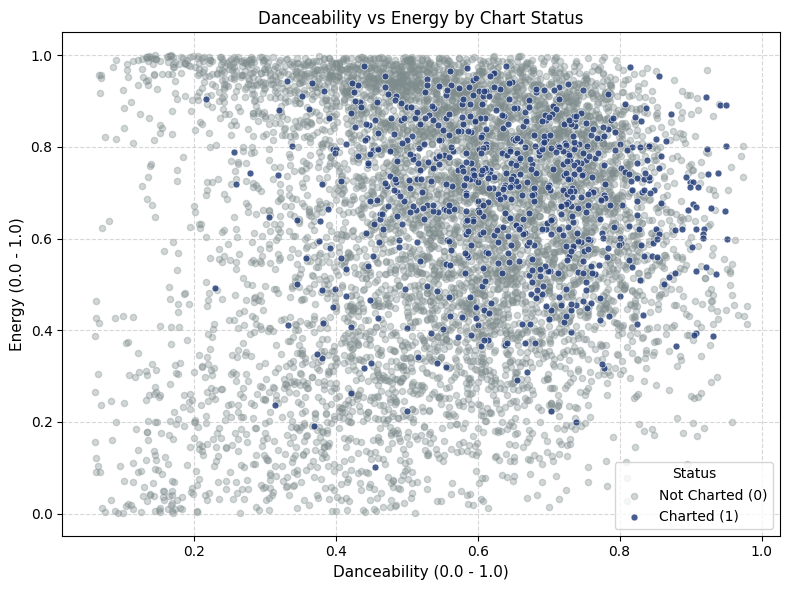

In [6]:
fig4 = plot_danceability_vs_energy(df, save_path="../reports/figures/danceability_vs_energy.png")


**Interpretation:**
Charted songs cluster prominently in the upper-right quadrant of high danceability (> 0.5) and high energy (> 0.5), aligning with commercial radio and streaming production conventions. However, thousands of non-charted songs also populate this identical region, resulting in substantial visual and statistical overlap. While high danceability and energy appear to be typical traits of commercial singles, they are far from sufficient criteria for achieving chart success.


## 6. Audio Feature Correlations

Pearson correlation matrix computed strictly across numeric audio features (excluding target, genre, and metadata).


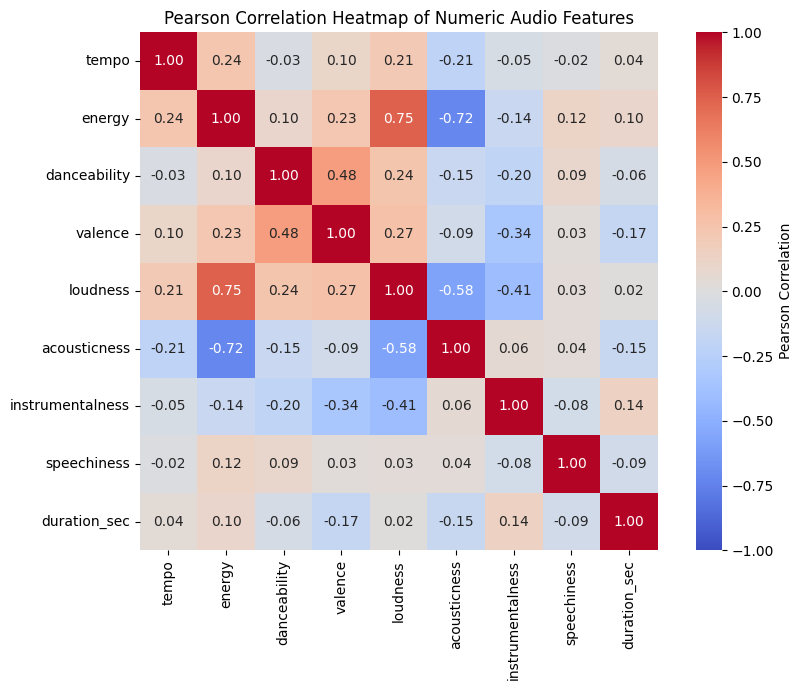

In [7]:
fig5 = plot_correlation_heatmap(df, save_path="../reports/figures/correlation_heatmap.png")


**Interpretation:**
Among numeric audio features, the strongest linear relationships exist between loudness and energy (r = 0.72) and an inverse relationship between loudness and acousticness (r = -0.56). Most other feature pairs exhibit weak or moderate correlation (|r| < 0.35), indicating minimal pairwise collinearity among candidate predictors. Downstream models should account for the expected co-variation among energy, loudness, and acousticness during feature scaling and interpretation.


## 7. Duration by Chart Year (Billboard-Charted Songs)

Median duration with interquartile range (IQR) band across Billboard chart years for charted songs (`charted == 1`).


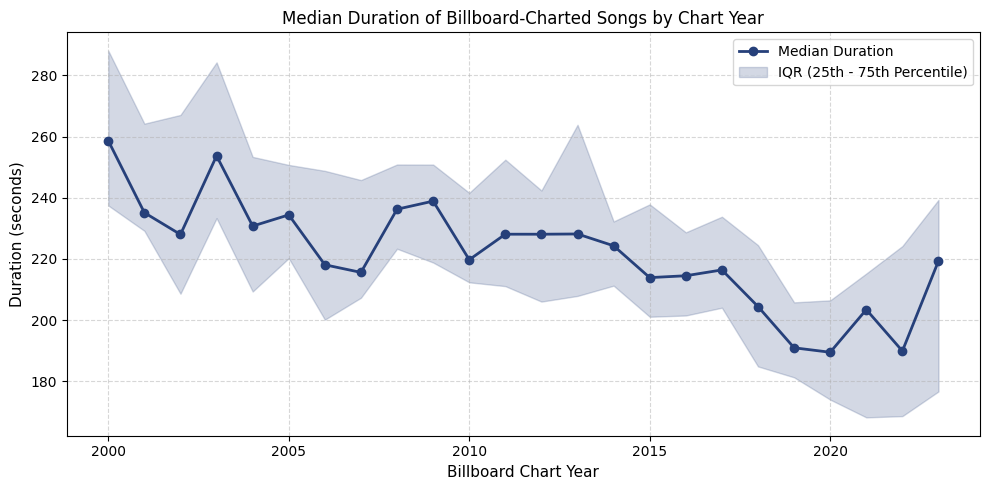

In [8]:
fig6 = plot_duration_by_year(df, save_path="../reports/figures/duration_by_year.png")


**Interpretation:**
Median song duration among Billboard-charted tracks remains relatively stable around 220–240 seconds from 2000 through the mid-2010s, before exhibiting a visible decline toward approximately 180–200 seconds in recent chart years (2018–2023). Crucially, `chart_year` represents the year associated with the Billboard chart record and should not be interpreted as the original release year of the recording. Furthermore, because chart_year is unobserved for non-charted songs and may reflect changes in streaming platform monetization rather than intrinsic musical trends, this figure alone does not support causal claims about track duration.


## 8. Small-Multiple Feature Boxplots

Distributions of each numeric audio feature split by target class (`charted`).


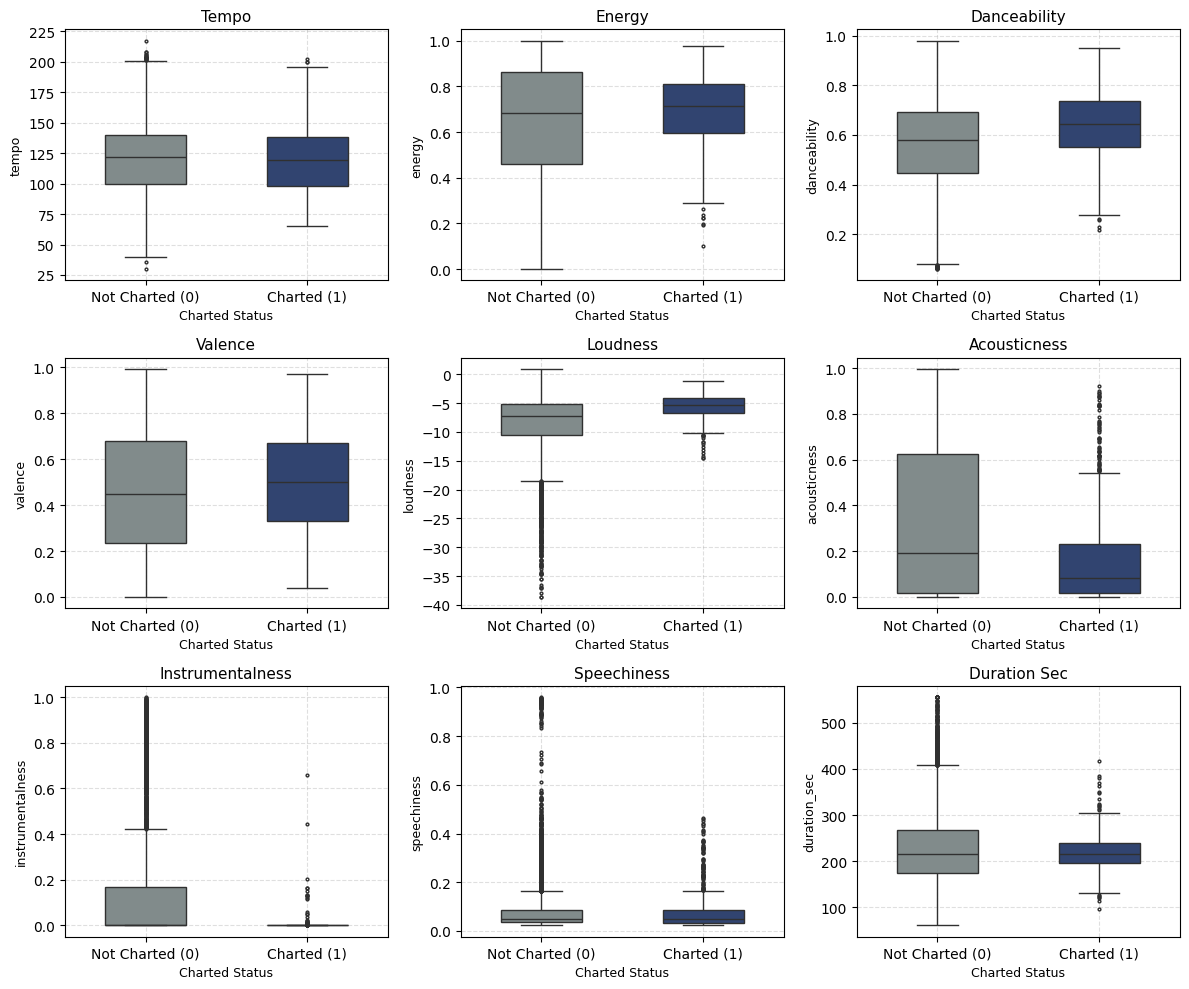

In [9]:
fig7 = plot_feature_boxplots(df, save_path="../reports/figures/feature_boxplots.png")


**Interpretation:**
Across the nine numeric audio features, charted songs exhibit slightly higher median loudness (r = 0.168, p = 7.08e-48) and danceability (r = 0.134, p = 3.71e-31), alongside lower instrumentalness (r = -0.164, p = 9.92e-46) and acousticness (r = -0.139, p = 3.08e-33). Despite statistically significant differences driven by large sample size, every feature displays substantial interquartile range overlap and numerous shared outliers between classes. No individual feature acts as a decisive threshold, demonstrating that hit prediction requires non-linear multivariate modeling.


## 9. Target Point-Biserial Correlations

Evaluation of linear association between each numeric audio feature and the binary target `charted`.


In [10]:
corr_table = compute_target_correlations(df, save_path="../reports/tables/target_correlations.csv")
print(corr_table.to_string(index=False))


         feature  correlation      p_value
        loudness     0.167783 7.075515e-48
instrumentalness    -0.163885 9.918424e-46
    acousticness    -0.138953 3.077639e-33
    danceability     0.134335 3.709020e-31
          energy     0.062295 8.130738e-08
         valence     0.047825 3.845684e-05
    duration_sec    -0.034767 2.773229e-03
     speechiness    -0.015654 1.780755e-01
           tempo    -0.015209 1.907184e-01


## 10. Dataset Summary & Integrity Checks


In [11]:
charted_count = int((df['charted'] == 1).sum())
non_charted_count = int((df['charted'] == 0).sum())
charted_obs_duration = int(df[df['charted'] == 1]['chart_year'].notnull().sum())

print("=== Summary Verification ===")
print(f"Total rows used: {len(df)}")
print(f"Charted count: {charted_count}")
print(f"Non-charted count: {non_charted_count}")
print(f"Charted percentage: {(charted_count / len(df)) * 100:.2f}%")
print(f"Non-charted percentage: {(non_charted_count / len(df)) * 100:.2f}%")
print(f"Numeric audio features ({len(AUDIO_FEATURES)}): {AUDIO_FEATURES}")
print(f"Missing values in modelling features: {df[AUDIO_FEATURES].isnull().sum().to_dict()}")
print(f"Whether chart_year contains missing values: {df['chart_year'].isnull().any()} ({df['chart_year'].isnull().sum()} nulls)")
print(f"Number of charted observations used in duration_by_year: {charted_obs_duration}")


=== Summary Verification ===
Total rows used: 7403
Charted count: 673
Non-charted count: 6730
Charted percentage: 9.09%
Non-charted percentage: 90.91%
Numeric audio features (9): ['tempo', 'energy', 'danceability', 'valence', 'loudness', 'acousticness', 'instrumentalness', 'speechiness', 'duration_sec']
Missing values in modelling features: {'tempo': 0, 'energy': 0, 'danceability': 0, 'valence': 0, 'loudness': 0, 'acousticness': 0, 'instrumentalness': 0, 'speechiness': 0, 'duration_sec': 0}
Whether chart_year contains missing values: True (6733 nulls)
Number of charted observations used in duration_by_year: 670
